In [2]:
!pip install lightgbm
!pip install catboost


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
!pip install lightgbm imbalanced-learn -q


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, roc_curve,
    classification_report, f1_score
)

# SMOTE
from imblearn.over_sampling import SMOTE

# Classifiers
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb
from sklearn.neural_network import MLPClassifier

# AutoEncoder
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

print('✅ Semua library berhasil diimport.')

✅ Semua library berhasil diimport.


In [5]:
df = pd.read_csv('creditcard1.csv')
print(f"Shape dataset: {df.shape}")
df.head()

Shape dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Transaksi Sah (0)      : 284315 (99.827%)
Transaksi Penipuan (1) : 492 (0.173%)


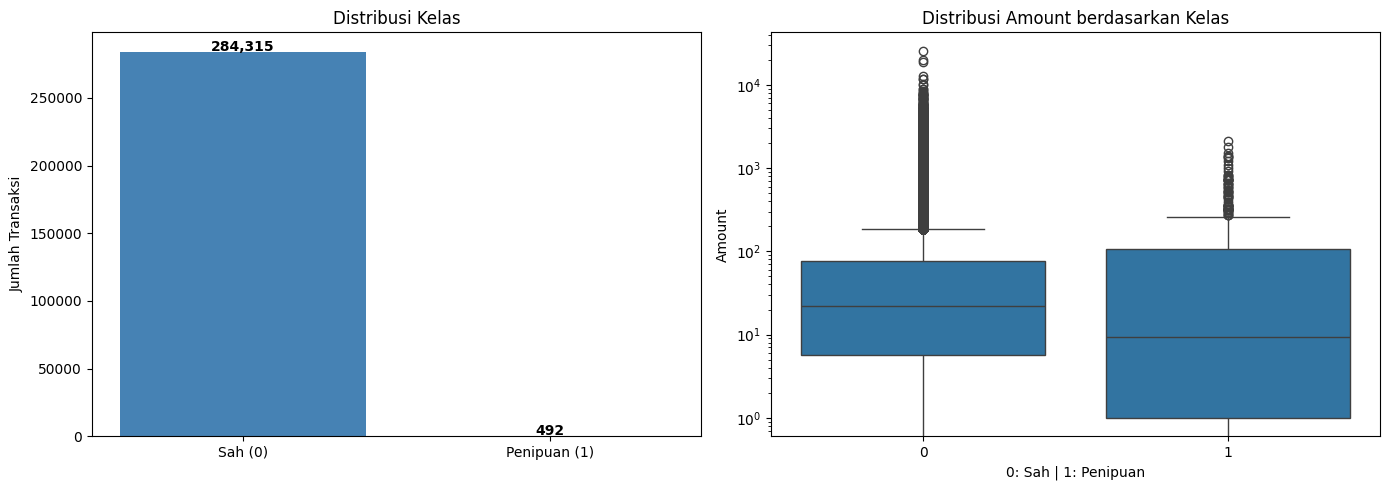

In [6]:
class_counts = df['Class'].value_counts()
print(f"Transaksi Sah (0)      : {class_counts[0]} ({class_counts[0]/len(df)*100:.3f}%)")
print(f"Transaksi Penipuan (1) : {class_counts[1]} ({class_counts[1]/len(df)*100:.3f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi kelas
axes[0].bar(['Sah (0)', 'Penipuan (1)'], [class_counts[0], class_counts[1]],
            color=['steelblue', 'tomato'])
axes[0].set_title('Distribusi Kelas')
axes[0].set_ylabel('Jumlah Transaksi')
for i, v in enumerate([class_counts[0], class_counts[1]]):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Distribusi amount
sns.boxplot(x=df['Class'], y=df['Amount'], ax=axes[1])
axes[1].set_title('Distribusi Amount berdasarkan Kelas')
axes[1].set_xlabel('0: Sah | 1: Penipuan')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

In [7]:
# Handle missing values
if df.isnull().sum().max() > 0:
    df = df.fillna(df.mean())
    print("Missing values diisi dengan mean.")
else:
    print("Tidak ada missing values.")

X = df.drop(['Class', 'Time'], axis=1).values
y = df['Class'].values

print(f"Shape X : {X.shape}")
print(f"Shape y : {y.shape}")

Tidak ada missing values.
Shape X : (284807, 29)
Shape y : (284807,)


SPLIT

In [8]:
from sklearn.model_selection import train_test_split

# Tahap 1: pisahkan Test (10% dari total data) - hold-out akhir, fixed
X_train_val, X_test_final, y_train_val, y_test_final = train_test_split(
    X, y,
    test_size=0.10,
    stratify=y,
    random_state=42
)

# Tahap 2: dari sisa 90%, pisahkan Val (10% dari TOTAL data = 1/9 dari sisa 90%)
# Val ini FIXED - dipakai konsisten untuk threshold tuning di semua fold CV
# dan juga untuk model final. Tidak pernah dirotasi seperti k-fold biasa.
X_train_full, X_val_fixed, y_train_full, y_val_fixed = train_test_split(
    X_train_val, y_train_val,
    test_size=(0.10 / 0.90),
    stratify=y_train_val,
    random_state=42
)

print("Train Set      :", X_train_full.shape, " (untuk 5-fold CV)")
print("Validation Set :", X_val_fixed.shape, " (fixed, untuk threshold tuning)")
print("Test Set       :", X_test_final.shape, " (fixed, hold-out akhir)")
print(f"Fraud -> Train: {sum(y_train_full)} | Val: {sum(y_val_fixed)} | Test: {sum(y_test_final)}")


Train Set      : (227845, 29)  (untuk 5-fold CV)
Validation Set : (28481, 29)  (fixed, untuk threshold tuning)
Test Set       : (28481, 29)  (fixed, hold-out akhir)
Fraud -> Train: 394 | Val: 49 | Test: 49


In [32]:
LATENT_DIM    = 256   # dimensi latent space AutoEncoder (tetap 256)
N_FEATURES_IG = 150   # jumlah fitur yang dipertahankan setelah seleksi Information Gain

def build_autoencoder(input_dim):
    """AutoEncoder — sama untuk semua model & semua fold."""
    inp     = Input(shape=(input_dim,))
    enc     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(inp)
    latent  = Dense(LATENT_DIM, activation='relu', kernel_regularizer=l2(0.001))(enc)
    dec     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(latent)
    out     = Dense(input_dim, activation='linear')(dec)

    ae      = Model(inputs=inp, outputs=out)
    encoder = Model(inputs=inp, outputs=latent)
    ae.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy')
    return ae, encoder


def extract_hybrid_features(ae, encoder, X_tr, X_te):
    """Gabung: Original Features + Latent Space + MSE Reconstruction Error."""
    mse_tr  = np.mean(np.power(X_tr - ae.predict(X_tr, verbose=0), 2), axis=1, keepdims=True)
    mse_te  = np.mean(np.power(X_te - ae.predict(X_te, verbose=0), 2), axis=1, keepdims=True)
    lat_tr  = encoder.predict(X_tr, verbose=0)
    lat_te  = encoder.predict(X_te, verbose=0)
    return np.hstack((X_tr, lat_tr, mse_tr)), np.hstack((X_te, lat_te, mse_te))


def extract_hybrid_single(ae, encoder, X):
    """
    Sama seperti extract_hybrid_features, tapi untuk SATU dataset saja.
    Dipakai untuk transform Val/Test fixed yang TIDAK ikut training
    (mis. Val fixed 10% yang ditransform pakai scaler/AE fold/final
    yang sedang aktif, tanpa perlu pasangan dataset lain).
    """
    mse = np.mean(np.power(X - ae.predict(X, verbose=0), 2), axis=1, keepdims=True)
    lat = encoder.predict(X, verbose=0)
    return np.hstack((X, lat, mse))


def apply_smote(X_hybrid_train, y_train, fold_num):
    """
    SMOTE diterapkan HANYA pada X_train_hybrid (Pilihan B).
    X_test tidak disentuh — tetap distribusi asli.
    """
    sm = SMOTE(random_state=42, k_neighbors=5)
    X_res, y_res = sm.fit_resample(X_hybrid_train, y_train)
    fraud_before = int(np.sum(y_train == 1))
    fraud_after  = int(np.sum(y_res == 1))
    print(f'[Fold {fold_num}] SMOTE: fraud {fraud_before} → {fraud_after} | '
          f'total train {len(y_train)} → {len(y_res)}')
    return X_res, y_res


def select_top_features_ig(X_fit, y_fit, k=N_FEATURES_IG, random_state=42):
    """
    Seleksi fitur dengan Information Gain (mutual information) antara
    setiap fitur hybrid dengan label.

    PENTING (anti-leakage): fungsi ini WAJIB di-fit HANYA dari data
    fit/train (sebelum SMOTE, sebelum dilihat oleh threshold-set,
    validation-set, maupun test-set). Indeks fitur yang terpilih dari
    sini baru kemudian diterapkan (transform saja, tanpa fit ulang) ke
    set-set lainnya.
    """
    ig_scores = mutual_info_classif(X_fit, y_fit, random_state=random_state)
    top_idx   = np.argsort(ig_scores)[::-1][:k]
    return top_idx, ig_scores


RECALL_WEIGHT = 0.70
def find_optimal_threshold(model, X_val, y_val, weight=RECALL_WEIGHT):
    prob = model.predict_proba(X_val)[:,1]
    fpr, tpr, thresholds = roc_curve(y_val, prob)

    j_scores = (weight * tpr) - ((1 - weight) * fpr)
    best_t = thresholds[np.argmax(j_scores)]

    return best_t


print('Fungsi helper siap.')

Fungsi helper siap.


SPLIT DATA 80/10/10 (Train 80% di-CV, Val & Test fixed)

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {
    'AE + XGBoost'       : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + Random Forest' : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + Catboost'       : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + LightGBM'       : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + MLP'            : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
}

# PERBAIKAN: simpan threshold tiap fold di sini supaya nanti bisa
# benar-benar dirata-rata dari 5 fold (sebelumnya t1..t5 ketimpa terus
# tiap fold sehingga rata-ratanya cuma nilai fold terakhir).
fold_thresholds = {
    'AE + XGBoost'       : [],
    'AE + Random Forest' : [],
    'AE + CatBoost'       : [],
    'AE + LightGBM'       : [],
    'AE + MLP'            : [],
}

fold_ig_indices = []   # simpan indeks fitur terpilih (Information Gain) tiap fold

last_fold = {}

for fold_num, (train_idx, val_idx) in enumerate(
    skf.split(X_train_full, y_train_full),
    start=1
):
    print(f'\n{"="*55}')
    print(f'                   FOLD {fold_num} / 5')
    print(f'{"="*55}')

    X_train_raw = X_train_full[train_idx]
    X_val_raw   = X_train_full[val_idx]

    y_train = y_train_full[train_idx]
    y_val   = y_train_full[val_idx]

    # ── Scaling ──────────────────────────────────────────────
    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_val   = scaler.transform(X_val_raw)

    print(f'Train: {X_train.shape} | Validation: {X_val.shape}')
    print(f'Fraud di train: {sum(y_train)} | Fraud di validation: {sum(y_val)}')

    # ── AutoEncoder ───────────────────────────────────────────
    # Ditraining hanya dengan data NORMAL (Class=0)
    X_train_normal = X_train[y_train == 0]
    ae, encoder = build_autoencoder(X_train.shape[1])
    ae.fit(
        X_train_normal, X_train_normal,
        epochs=50, batch_size=64, validation_split=0.1,
        callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                 restore_best_weights=True)],
        verbose=0
    )
    print(f'[Fold {fold_num}] AutoEncoder selesai (training dari data normal saja).')

    # ── Ekstraksi Fitur Hybrid ────────────────────────────────
    X_train_hybrid, X_val_hybrid = extract_hybrid_features(
        ae, encoder, X_train, X_val
    )
    print(f'[Fold {fold_num}] Dimensi hybrid: {X_train_hybrid.shape[1]} fitur')

    # ── Transform Val FIXED (eksternal, 10% dari total data) ───
    # Val ini TIDAK ikut training fold manapun. Dipakai konsisten untuk
    # threshold tuning, ditransform pakai scaler & AE dari fold ini saja
    # (transform, bukan fit ulang -> anti-leakage).
    X_val_fixed_scaled = scaler.transform(X_val_fixed)
    X_thresh_hybrid    = extract_hybrid_single(ae, encoder, X_val_fixed_scaled)
    y_thresh            = y_val_fixed
    print(f'[Fold {fold_num}] Fit (training): {X_train_hybrid.shape[0]} | '
          f'Threshold-tuning (Val fixed): {X_thresh_hybrid.shape[0]} | '
          f'Val (evaluasi fold): {X_val_hybrid.shape[0]}')

    # ── Seleksi Fitur dengan Information Gain ──────────────────
    # Di-fit dari SELURUH X_train_hybrid & y_train fold ini (sebelum SMOTE,
    # sebelum dilihat oleh Val fixed / val fold) supaya tidak ada data leakage.
    ig_idx, ig_scores = select_top_features_ig(X_train_hybrid, y_train, k=N_FEATURES_IG)
    X_train_hybrid  = X_train_hybrid[:, ig_idx]
    X_val_hybrid    = X_val_hybrid[:, ig_idx]
    X_thresh_hybrid = X_thresh_hybrid[:, ig_idx]
    fold_ig_indices.append(ig_idx)
    print(f'[Fold {fold_num}] Information Gain: 286 -> '
          f'{X_train_hybrid.shape[1]} fitur terpilih')

    # ── SMOTE ─────────────────────────────────────
    # SMOTE diaplikasikan ke SELURUH data training fold ini
    # (BUKAN ke Val fixed/threshold-set, BUKAN ke val fold)
    X_tr, y_tr = apply_smote(
        X_train_hybrid,
        y_train,
        fold_num
    )

    # ════════════════════════════════════════
    # MODEL 1 — AE + XGBoost
    # ════════════════════════════════════════
    m1 = xgb.XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=6,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
        random_state=42, eval_metric='auc', verbosity=0
    )
    m1.fit(X_tr, y_tr)
    t1 = find_optimal_threshold(m1, X_thresh_hybrid, y_thresh)
    prob1 = m1.predict_proba(X_val_hybrid)[:,1]
    pred1 = (prob1 >= t1).astype(int)
    results['AE + XGBoost']['acc'].append(accuracy_score(y_val, pred1)*100)
    results['AE + XGBoost']['prec'].append(precision_score(y_val, pred1, zero_division=0)*100)
    results['AE + XGBoost']['dr'].append(recall_score(y_val, pred1)*100)
    results['AE + XGBoost']['auc'].append(roc_auc_score(y_val, prob1)*100)
    results['AE + XGBoost']['f1'].append(f1_score(y_val, pred1, zero_division=0)*100)
    fold_thresholds['AE + XGBoost'].append(t1)
    print(f'[Fold {fold_num}] XGBoost      Acc:{results["AE + XGBoost"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + XGBoost"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + XGBoost"]["auc"][-1]:.2f}% '
          f'(threshold={t1:.3f})')

    # ════════════════════════════════════════
    # MODEL 2 — AE + Random Forest
    # ════════════════════════════════════════
    m2 = RandomForestClassifier(
        n_estimators=200, max_depth=None,
        n_jobs=-1, random_state=42
        # Tidak pakai class_weight karena SMOTE sudah balance
    )
    m2.fit(X_tr, y_tr)
    t2    = find_optimal_threshold(m2, X_thresh_hybrid, y_thresh)
    prob2 = m2.predict_proba(X_val_hybrid)[:, 1]
    pred2 = (prob2 >= t2).astype(int)
    results['AE + Random Forest']['acc'].append(accuracy_score(y_val, pred2)*100)
    results['AE + Random Forest']['prec'].append(precision_score(y_val, pred2, zero_division=0)*100)
    results['AE + Random Forest']['dr'].append(recall_score(y_val, pred2)*100)
    results['AE + Random Forest']['auc'].append(roc_auc_score(y_val, prob2)*100)
    results['AE + Random Forest']['f1'].append(f1_score(y_val, pred2, zero_division=0)*100)
    fold_thresholds['AE + Random Forest'].append(t2)
    print(f'[Fold {fold_num}] Rnd Forest   Acc:{results["AE + Random Forest"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + Random Forest"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + Random Forest"]["auc"][-1]:.2f}% '
          f'(threshold={t2:.3f})')

    # ════════════════════════════════════════
    # MODEL 3 — AE + Catboost
    # ════════════════════════════════════════
    m3 = CatBoostClassifier(
        iterations=200,
        learning_rate=0.05,
        depth=6,
        random_state=42,
        verbose=0
    )
    m3.fit(X_tr, y_tr)
    t3    = find_optimal_threshold(m3, X_thresh_hybrid, y_thresh)
    prob3 = m3.predict_proba(X_val_hybrid)[:, 1]
    pred3 = (prob3 >= t3).astype(int)
    results['AE + Catboost']['acc'].append(accuracy_score(y_val, pred3)*100)
    results['AE + Catboost']['prec'].append(precision_score(y_val, pred3, zero_division=0)*100)
    results['AE + Catboost']['dr'].append(recall_score(y_val, pred3)*100)
    results['AE + Catboost']['auc'].append(roc_auc_score(y_val, prob3)*100)
    results['AE + Catboost']['f1'].append(f1_score(y_val, pred3, zero_division=0)*100)
    fold_thresholds['AE + CatBoost'].append(t3)
    print(f'[Fold {fold_num}] Catboost          Acc:{results["AE + Catboost"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + Catboost"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + Catboost"]["auc"][-1]:.2f}% '
          f'(threshold={t3:.3f})')

    # ════════════════════════════════════════
    # MODEL 4 — AE + LightGBM
    # ════════════════════════════════════════
    m4 = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.05,
        max_depth=6, subsample=0.8, colsample_bytree=0.8,
        is_unbalance=False,   # False karena SMOTE sudah handle
        random_state=42, verbose=-1
    )
    m4.fit(X_tr, y_tr)
    t4    = find_optimal_threshold(m4, X_thresh_hybrid, y_thresh)
    prob4 = m4.predict_proba(X_val_hybrid)[:, 1]
    pred4 = (prob4 >= t4).astype(int)
    results['AE + LightGBM']['acc'].append(accuracy_score(y_val, pred4)*100)
    results['AE + LightGBM']['prec'].append(precision_score(y_val, pred4, zero_division=0)*100)
    results['AE + LightGBM']['dr'].append(recall_score(y_val, pred4)*100)
    results['AE + LightGBM']['auc'].append(roc_auc_score(y_val, prob4)*100)
    results['AE + LightGBM']['f1'].append(f1_score(y_val, pred4, zero_division=0)*100)
    fold_thresholds['AE + LightGBM'].append(t4)
    print(f'[Fold {fold_num}] LightGBM     Acc:{results["AE + LightGBM"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + LightGBM"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + LightGBM"]["auc"][-1]:.2f}% '
          f'(threshold={t4:.3f})')

    # ════════════════════════════════════════
    # MODEL 5 — AE + MLP
    # ════════════════════════════════════════
    m5 = MLPClassifier(
        hidden_layer_sizes=(256, 128, 64),
        activation='relu', solver='adam',
        learning_rate_init=0.001, max_iter=200,
        early_stopping=True, validation_fraction=0.1,
        random_state=42
    )
    m5.fit(X_tr, y_tr)
    t5    = find_optimal_threshold(m5, X_thresh_hybrid, y_thresh)
    prob5 = m5.predict_proba(X_val_hybrid)[:, 1]
    pred5 = (prob5 >= t5).astype(int)
    results['AE + MLP']['acc'].append(accuracy_score(y_val, pred5)*100)
    results['AE + MLP']['prec'].append(precision_score(y_val, pred5, zero_division=0)*100)
    results['AE + MLP']['dr'].append(recall_score(y_val, pred5)*100)
    results['AE + MLP']['auc'].append(roc_auc_score(y_val, prob5)*100)
    results['AE + MLP']['f1'].append(f1_score(y_val, pred5, zero_division=0)*100)
    fold_thresholds['AE + MLP'].append(t5)
    print(f'[Fold {fold_num}] MLP          Acc:{results["AE + MLP"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + MLP"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + MLP"]["auc"][-1]:.2f}% '
          f'(threshold={t5:.3f})')

    if fold_num == 5:
        last_fold = {
            'AE + XGBoost'       : (y_val, pred1, prob1),
            'AE + Random Forest' : (y_val, pred2, prob2),
            'AE + Catboost'      : (y_val, pred3, prob3),
            'AE + LightGBM'      : (y_val, pred4, prob4),
            'AE + MLP'           : (y_val, pred5, prob5),
        }

print('\n' + '='*55)
print('Training & evaluasi selesai untuk semua fold.')
print('='*55)


                   FOLD 1 / 5
Train: (182276, 29) | Validation: (45569, 29)
Fraud di train: 316 | Fraud di validation: 78
[Fold 1] AutoEncoder selesai (training dari data normal saja).
[Fold 1] Dimensi hybrid: 286 fitur
[Fold 1] Fit (training): 182276 | Threshold-tuning (Val fixed): 28481 | Val (evaluasi fold): 45569
[Fold 1] Information Gain: 286 -> 150 fitur terpilih
[Fold 1] SMOTE: fraud 316 → 181960 | total train 182276 → 363920
[Fold 1] XGBoost      Acc:97.14% DR:88.46% AUC:98.25% (threshold=0.006)
[Fold 1] Rnd Forest   Acc:99.20% DR:87.18% AUC:97.07% (threshold=0.040)
[Fold 1] Catboost          Acc:98.25% DR:85.90% AUC:96.85% (threshold=0.033)
[Fold 1] LightGBM     Acc:98.02% DR:89.74% AUC:97.44% (threshold=0.006)
[Fold 1] MLP          Acc:95.53% DR:88.46% AUC:95.30% (threshold=0.000)

                   FOLD 2 / 5
Train: (182276, 29) | Validation: (45569, 29)
Fraud di train: 315 | Fraud di validation: 79
[Fold 2] AutoEncoder selesai (training dari data normal saja).
[Fold 2] Di

In [11]:
print("\n" + "="*60)
print("AVERAGE 5-FOLD CROSS VALIDATION RESULTS")
print("="*60)

for model_name, metrics in results.items():
    print(f"\n{model_name}")
    print(f"Accuracy : {np.mean(metrics['acc']):.4f} ± {np.std(metrics['acc']):.4f}")
    print(f"Recall   : {np.mean(metrics['dr']):.4f} ± {np.std(metrics['dr']):.4f}")
    print(f"AUC      : {np.mean(metrics['auc']):.4f} ± {np.std(metrics['auc']):.4f}")


AVERAGE 5-FOLD CROSS VALIDATION RESULTS

AE + XGBoost
Accuracy : 89.8080 ± 5.6206
Recall   : 94.4012 ± 3.3140
AUC      : 98.1620 ± 0.6418

AE + Random Forest
Accuracy : 92.0332 ± 5.0926
Recall   : 93.3853 ± 3.6706
AUC      : 97.3548 ± 0.9270

AE + Catboost
Accuracy : 89.5578 ± 6.4857
Recall   : 93.1289 ± 3.6157
AUC      : 97.6862 ± 0.8994

AE + LightGBM
Accuracy : 89.3528 ± 7.9475
Recall   : 93.8981 ± 2.9667
AUC      : 97.9056 ± 0.5597

AE + MLP
Accuracy : 95.2055 ± 3.0674
Recall   : 88.3252 ± 4.3396
AUC      : 96.2180 ± 1.4603


In [33]:
# PERBAIKAN: fold_thresholds sekarang berisi 5 nilai per model (1 per fold),
# jadi best_thresholds di bawah ini adalah RATA-RATA SUNGGUHAN dari 5 fold,
# bukan cuma nilai dari fold terakhir seperti sebelumnya.
best_thresholds = {
    k: np.mean(v)
    for k, v in fold_thresholds.items()
}

print("Threshold rata-rata (dari 5 fold):")
for k, v in best_thresholds.items():
    per_fold = ", ".join(f"{x:.3f}" for x in fold_thresholds[k])
    print(f"  {k:<20}: {v:.4f}   (per-fold: {per_fold})")

Threshold rata-rata (dari 5 fold):
  AE + XGBoost        : 0.0020   (per-fold: 0.006, 0.001, 0.001, 0.002, 0.001)
  AE + Random Forest  : 0.0150   (per-fold: 0.040, 0.010, 0.010, 0.005, 0.010)
  AE + CatBoost       : 0.0096   (per-fold: 0.033, 0.004, 0.001, 0.002, 0.009)
  AE + LightGBM       : 0.0019   (per-fold: 0.006, 0.000, 0.000, 0.001, 0.002)
  AE + MLP            : 0.0002   (per-fold: 0.000, 0.000, 0.001, 0.000, 0.000)


In [34]:
scaler = StandardScaler()

X_train_scaled    = scaler.fit_transform(X_train_full)
X_test_scaled     = scaler.transform(X_test_final)
X_val_fixed_scaled_final = scaler.transform(X_val_fixed)


In [35]:
X_train_normal = X_train_scaled[y_train_full == 0]

ae, encoder = build_autoencoder(X_train_scaled.shape[1])

ae.fit(
    X_train_normal,
    X_train_normal,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - loss: -2.3804 - val_loss: -2.9356
Epoch 2/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - loss: -3.0979 - val_loss: -3.6835
Epoch 3/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - loss: -3.9791 - val_loss: -4.3652
Epoch 4/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - loss: -4.4025 - val_loss: -4.4109
Epoch 5/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - loss: -4.2957 - val_loss: -4.2134
Epoch 6/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - loss: -4.0359 - val_loss: -4.1038
Epoch 7/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - loss: -4.2419 - val_loss: -4.5028
Epoch 8/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - loss: -4.4229 - val_loss: -4.3320
Epoch 9/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: -4.6377 - val_loss: -4.6245
Epoch 10/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - loss: -4.5837 - val_loss: -4.1834
Epoch 11/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: -4.5591 - val_loss: -4.59

In [36]:
X_train_hybrid, X_test_hybrid = extract_hybrid_features(
    ae,
    encoder,
    X_train_scaled,
    X_test_scaled
)

# Transform Val fixed (10%) juga, pakai AE & encoder model final ini
X_val_fixed_hybrid_final = extract_hybrid_single(ae, encoder, X_val_fixed_scaled_final)


### Seleksi Fitur dengan Information Gain (Model Final)

In [37]:
# ── Seleksi Fitur dengan Information Gain (Final Model) ──────────
# Di-fit HANYA dari X_train_hybrid & y_train_full (train set, SEBELUM SMOTE),
# TIDAK dari X_test_hybrid, supaya test set benar-benar unseen (anti-leakage).

original_feature_names = df.drop(['Class', 'Time'], axis=1).columns.tolist()
hybrid_feature_names = (
    original_feature_names
    + [f'Latent_{i+1}' for i in range(LATENT_DIM)]
    + ['MSE_Reconstruction']
)

final_ig_idx, final_ig_scores = select_top_features_ig(
    X_train_hybrid, y_train_full, k=N_FEATURES_IG
)

print(f"Information Gain (final model): {X_train_hybrid.shape[1]} -> "
      f"{len(final_ig_idx)} fitur terpilih")

X_train_hybrid           = X_train_hybrid[:, final_ig_idx]
X_test_hybrid            = X_test_hybrid[:, final_ig_idx]
X_val_fixed_hybrid_final = X_val_fixed_hybrid_final[:, final_ig_idx]

n_orig_selected   = sum(1 for i in final_ig_idx if i < len(original_feature_names))
n_latent_selected = sum(
    1 for i in final_ig_idx
    if len(original_feature_names) <= i < len(original_feature_names) + LATENT_DIM
)
n_mse_selected    = sum(1 for i in final_ig_idx if i == len(hybrid_feature_names) - 1)

print(f"  - Fitur asli (V1-V28, Amount) terpilih : {n_orig_selected} / {len(original_feature_names)}")
print(f"  - Fitur latent terpilih                : {n_latent_selected} / {LATENT_DIM}")
print(f"  - Fitur MSE reconstruction terpilih     : {n_mse_selected} / 1")

Information Gain (final model): 286 -> 150 fitur terpilih
  - Fitur asli (V1-V28, Amount) terpilih : 23 / 29
  - Fitur latent terpilih                : 126 / 256
  - Fitur MSE reconstruction terpilih     : 1 / 1


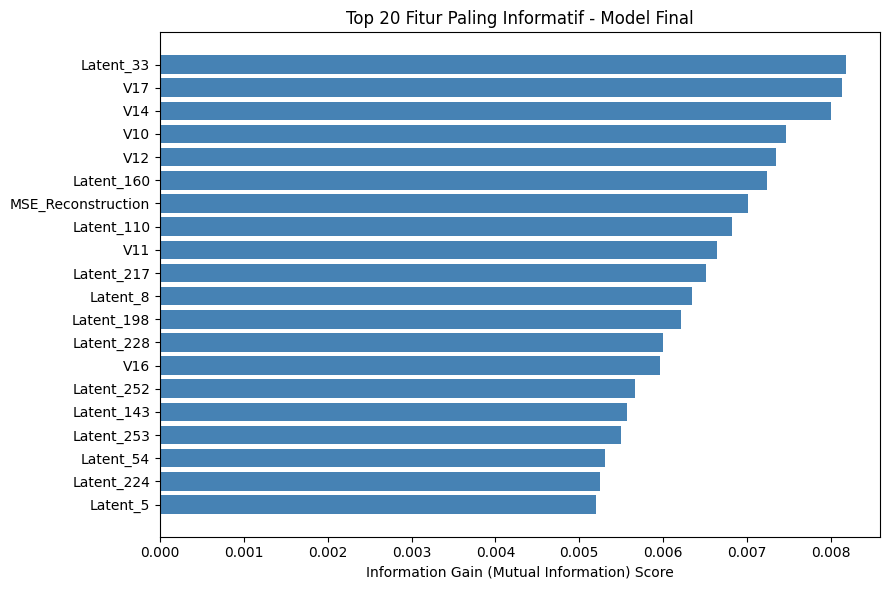

In [38]:
# ── Visualisasi Top 20 Fitur Paling Informatif (Information Gain) ──
top20_idx    = np.argsort(final_ig_scores)[::-1][:20]
top20_names  = [hybrid_feature_names[i] for i in top20_idx]
top20_scores = final_ig_scores[top20_idx]

plt.figure(figsize=(9, 6))
plt.barh(top20_names[::-1], top20_scores[::-1], color='steelblue')
plt.xlabel('Information Gain (Mutual Information) Score')
plt.title('Top 20 Fitur Paling Informatif - Model Final')
plt.tight_layout()
plt.show()

In [39]:
X_train_smote, y_train_smote = apply_smote(
    X_train_hybrid,
    y_train_full,
    fold_num=0
)

[Fold 0] SMOTE: fraud 394 → 227451 | total train 227845 → 454902


In [40]:
m1 = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    verbosity=0
)
m1.fit(X_train_smote, y_train_smote)

m2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    n_jobs=-1,
    random_state=42
)
m2.fit(X_train_smote, y_train_smote)

m3 = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    random_state=42,
    verbose=0
)
m3.fit(X_train_smote, y_train_smote)

m4 = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    is_unbalance=False,
    random_state=42,
    verbose=-1
)
m4.fit(X_train_smote, y_train_smote)

m5 = MLPClassifier(
    hidden_layer_sizes=(256,128,64),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)
m5.fit(X_train_smote, y_train_smote)

,hidden_layer_sizes,"(256, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,42


In [41]:
final_models = {
    "AE + XGBoost": m1,
    "AE + Random Forest": m2,
    "AE + CatBoost": m3,
    "AE + LightGBM": m4,
    "AE + MLP": m5
}

### Threshold Final (di-tuning dari Val Fixed 10%)

In [42]:
# ── Threshold Final, di-tuning dari Val FIXED (10%) ───────────────
# Berbeda dari best_thresholds (rata-rata 5 fold CV), ini threshold yang
# di-tuning LANGSUNG dari model final (dilatih di seluruh Train 80%)
# terhadap Val fixed yang tidak pernah dilihat selama training model final.
final_thresholds = {
    name: find_optimal_threshold(model, X_val_fixed_hybrid_final, y_val_fixed)
    for name, model in final_models.items()
}

print("Perbandingan threshold:")
for k, v in final_thresholds.items():
    print(f"  {k:<20}: final={v:.4f}   |   rata-rata CV (5 fold)={best_thresholds[k]:.4f}")

Perbandingan threshold:
  AE + XGBoost        : final=0.0011   |   rata-rata CV (5 fold)=0.0020
  AE + Random Forest  : final=0.0200   |   rata-rata CV (5 fold)=0.0150
  AE + CatBoost       : final=0.0052   |   rata-rata CV (5 fold)=0.0096
  AE + LightGBM       : final=0.0011   |   rata-rata CV (5 fold)=0.0019
  AE + MLP            : final=0.0000   |   rata-rata CV (5 fold)=0.0002


In [43]:
from sklearn.metrics import classification_report

all_predictions = {}

print("\nFINAL HOLD-OUT TEST RESULTS")
print("="*60)

for name, model in final_models.items():

    prob = model.predict_proba(X_test_hybrid)[:,1]

    threshold = final_thresholds[name]   # pakai threshold dari Val fixed, bukan rata-rata CV

    pred = (prob >= threshold).astype(int)

    # simpan hasil prediksi
    all_predictions[name] = pred

    acc = accuracy_score(y_test_final, pred)*100
    dr  = recall_score(y_test_final, pred)*100
    auc = roc_auc_score(y_test_final, prob)*100

    print(
        f"{name:<20}"
        f" Acc={acc:.2f}%"
        f" | DR={dr:.2f}%"
        f" | AUC={auc:.2f}%"
    )


FINAL HOLD-OUT TEST RESULTS
AE + XGBoost         Acc=87.76% | DR=91.84% | AUC=97.01%


AE + Random Forest   Acc=97.34% | DR=89.80% | AUC=96.06%
AE + CatBoost        Acc=91.39% | DR=91.84% | AUC=97.55%
AE + LightGBM        Acc=90.27% | DR=91.84% | AUC=96.82%
AE + MLP             Acc=87.71% | DR=93.88% | AUC=97.52%


In [44]:
for name, pred in all_predictions.items():

    print("\n" + "="*70)
    print(name)
    print("="*70)

    print(
        classification_report(
            y_test_final,
            pred,
            digits=4
        )
    )


AE + XGBoost
              precision    recall  f1-score   support

           0     0.9998    0.8776    0.9347     28432
           1     0.0128    0.9184    0.0252        49

    accuracy                         0.8776     28481
   macro avg     0.5063    0.8980    0.4799     28481
weighted avg     0.9981    0.8776    0.9332     28481


AE + Random Forest
              precision    recall  f1-score   support

           0     0.9998    0.9735    0.9865     28432
           1     0.0551    0.8980    0.1039        49

    accuracy                         0.9734     28481
   macro avg     0.5275    0.9357    0.5452     28481
weighted avg     0.9982    0.9734    0.9850     28481


AE + CatBoost
              precision    recall  f1-score   support

           0     0.9998    0.9139    0.9549     28432
           1     0.0181    0.9184    0.0354        49

    accuracy                         0.9139     28481
   macro avg     0.5089    0.9161    0.4952     28481
weighted avg     0.9982  

In [24]:
print("XGB :", t1)
print("RF  :", t2)
print("CAT :", t3)
print("LGB :", t4)
print("MLP :", t5)

XGB : 0.000875039
RF  : 0.01
CAT : 0.00896877336214024
LGB : 0.0016644125624499621
MLP : 9.579835885678877e-08


In [25]:
print("XGB")
print(prob1.min(), prob1.max(), prob1.mean())

print("RF")
print(prob2.min(), prob2.max(), prob2.mean())

print("CAT")
print(prob3.min(), prob3.max(), prob3.mean())

print("LGB")
print(prob4.min(), prob4.max(), prob4.mean())

print("MLP")
print(prob5.min(), prob5.max(), prob5.mean())

XGB
2.3611316e-05 0.9998908 0.0031933242
RF
0.0 1.0 0.00362505211876495
CAT
9.222725813369238e-08 0.9999514187518025 0.004723432765076819
LGB
2.8923298945580575e-08 0.9998912526041501 0.00265804655481016
MLP
0.0 0.9999999999973421 0.0017362156314044445
